# Reconocimiento paralelo de tipos de punto de CROCHET

## Nuestro Proyecto de Cómputo Paralelo

**By**
- Montserrat Reyes Vasquez
- Diego Abisay Cruz Ceron

### Objetivo

Clasificar tres tipos de punto de crochet:

- Punto bajo
- Medio punto alto
- Punto alto

mediante características de textura LBP y GLCM y clasificadores tradicionales SVM y Random Forest.

Además, se comparará la extracción secuencial y paralela de características mediante tiempo de ejecución, speedup y eficiencia.

## 1. Importación de bibliotecas

La carga de las bibliotecas necesarias para explorar el conjunto de datos. Primera etapa: (todavía no se realiza extracción de
características ni entrenamiento de modelos.)

In [96]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RUTA_PROCEDENCIA = Path("procedencia.csv")

df = pd.read_csv(RUTA_PROCEDENCIA)

print("Total de imágenes:", len(df))
print("\nImágenes por clase:")
print(df["clase"].value_counts())

display(df.head())

Total de imágenes: 5300

Imágenes por clase:
clase
medio_punto_alto    3120
punto_alto          1160
punto_bajo          1020
Name: count, dtype: int64


,ruta,clase,muestra,grupo,foto_origen,tipo,x_original,y_original,lado_original,ancho_salida,alto_salida
0,dataset_crochet/medio_punto_alto/muestra_B_1_H...,medio_punto_alto,muestra_B_1_HD,medio_punto_alto/muestra_B_1_HD,crochet_organizado_provisional/dataset_crochet...,recorte,928,349,219,128,128
1,dataset_crochet/medio_punto_alto/muestra_B_1_H...,medio_punto_alto,muestra_B_1_HD,medio_punto_alto/muestra_B_1_HD,crochet_organizado_provisional/dataset_crochet...,recorte,1164,349,219,128,128
2,dataset_crochet/medio_punto_alto/muestra_B_1_H...,medio_punto_alto,muestra_B_1_HD,medio_punto_alto/muestra_B_1_HD,crochet_organizado_provisional/dataset_crochet...,recorte,1401,349,219,128,128
3,dataset_crochet/medio_punto_alto/muestra_B_1_H...,medio_punto_alto,muestra_B_1_HD,medio_punto_alto/muestra_B_1_HD,crochet_organizado_provisional/dataset_crochet...,recorte,1125,363,219,128,128
4,dataset_crochet/medio_punto_alto/muestra_B_1_H...,medio_punto_alto,muestra_B_1_HD,medio_punto_alto/muestra_B_1_HD,crochet_organizado_provisional/dataset_crochet...,recorte,1361,363,219,128,128


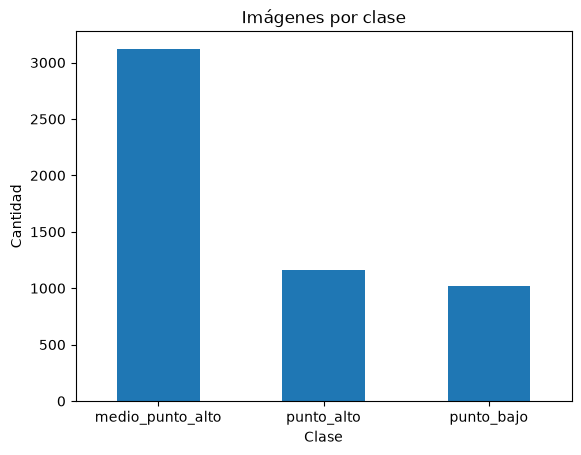

In [97]:
df["clase"].value_counts().plot(kind="bar")

plt.title("Imágenes por clase")
plt.xlabel("Clase")
plt.ylabel("Cantidad")
plt.xticks(rotation=0)
plt.show()

In [98]:
assert {"ruta", "clase", "grupo"}.issubset(df.columns)
assert not df[["ruta", "clase", "grupo"]].isna().any().any()
assert not df["ruta"].duplicated().any(), "Hay rutas repetidas."

faltantes = [ruta for ruta in df["ruta"] if not Path(ruta).is_file()]
assert not faltantes, f"Faltan {len(faltantes)} imágenes: {faltantes[:3]}"

assert df.groupby("grupo")["clase"].nunique().eq(1).all(), (
    "Un grupo tiene más de una clase."
)

print("Grupos por clase:")
print(df.groupby("clase")["grupo"].nunique())
print("Total de grupos:", df["grupo"].nunique())

Grupos por clase:
clase
medio_punto_alto    7
punto_alto          3
punto_bajo          3
Name: grupo, dtype: int64
Total de grupos: 13


## 2. Preprocesamiento y extracción de características

Convertimos las Imagenes a escala de grises para trabajar con información de textura. y asi depues se obtienen características mediante LBP y GLCM.

In [1]:
import time
import importlib
import numpy as np

In [4]:
importlib.invalidate_caches()
import funciones_crochet as fc
fc = importlib.reload(fc)

print("Módulo cargado:", fc.__file__)

Módulo cargado: c:\Users\monts\Downloads\Proyecto_ComputoParalelo_DACC_MRV-main\Proyecto_ComputoParalelo_DACC_MRV-main\funciones_crochet.py


In [102]:
ruta_prueba = df.iloc[0]["ruta"]
imagen = fc.preprocesar_imagen(ruta_prueba)
vector = fc.extraer_caracteristicas(ruta_prueba)

print("Tamaño de imagen:", imagen.shape)
print("LBP:", fc.extraer_lbp(imagen).size)
print("GLCM:", fc.extraer_glcm(imagen).size)
print("Total:", vector.size)

assert vector.shape == (34,)
assert np.isfinite(vector).all()

Tamaño de imagen: (128, 128)
LBP: 18
GLCM: 16
Total: 34


## 3. Extracción secuencial de características

Procesamos todas las imágenes una por una para obtener el tiempo base de ejecución. Este tiempo despues lo utilizaremos para calcular el speedup de la versión paralela.

In [103]:
rutas = df["ruta"].tolist()

inicio = time.perf_counter()
X = np.array([fc.extraer_caracteristicas(ruta) for ruta in rutas])
tiempo_secuencial = time.perf_counter() - inicio

assert X.shape == (len(df), 34)
assert np.isfinite(X).all()

print("Forma de X:", X.shape)
print(f"Tiempo secuencial: {tiempo_secuencial:.4f} s")

Forma de X: (5300, 34)
Tiempo secuencial: 156.9124 s


## 4. Extracción paralela de características

Ahora distibuimos el procesamiento de las imágenes entre varios procesos. para despues comparar los tiempos obtenidos con la ejecución secuencial para calcular speedup y eficiencia.

In [104]:
from joblib import Parallel, delayed, parallel_config


def ejecutar_paralelo(num_procesos):
    inicio = time.perf_counter()

    with parallel_config(
        backend="loky",
        n_jobs=num_procesos,
        inner_max_num_threads=1
    ):
        vectores = Parallel()(
            delayed(fc.extraer_caracteristicas)(ruta)
            for ruta in rutas
        )

    matriz = np.array(vectores)
    tiempo = time.perf_counter() - inicio
    return matriz, tiempo

In [105]:
resultados_paralelo = []

for p in [2, 4, 8]:
    Xp, tiempo_p = ejecutar_paralelo(p)

    assert Xp.shape == X.shape
    np.testing.assert_allclose(Xp, X, rtol=1e-10, atol=1e-12)

    speedup = tiempo_secuencial / tiempo_p
    eficiencia = speedup / p

    resultados_paralelo.append({
        "procesos": p,
        "tiempo": tiempo_p,
        "speedup": speedup,
        "eficiencia": eficiencia
    })

    print(
        f"{p} procesos | {tiempo_p:.4f} s | "
        f"speedup={speedup:.4f} | eficiencia={eficiencia:.4f}"
    )

del Xp

2 procesos | 82.4649 s | speedup=1.9028 | eficiencia=0.9514
4 procesos | 44.2910 s | speedup=3.5428 | eficiencia=0.8857
8 procesos | 36.2297 s | speedup=4.3310 | eficiencia=0.5414


In [106]:
#Tabla final
resultados = pd.DataFrame([
    {
        "procesos": 1,
        "tiempo": tiempo_secuencial,
        "speedup": 1.0,
        "eficiencia": 1.0
    },
    *resultados_paralelo
])

display(resultados)

,procesos,tiempo,speedup,eficiencia
0,1,156.912370,1.000000,1.000000
1,2,82.464884,1.902778,0.951389
2,4,44.290951,3.542764,0.885691
3,8,36.229727,4.331039,0.541380


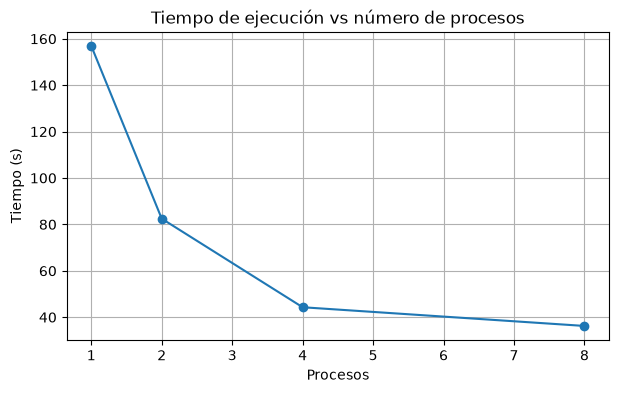

In [107]:
#Gráfica de tiempo
plt.figure(figsize=(7, 4))

plt.plot(
    resultados["procesos"],
    resultados["tiempo"],
    marker="o"
)

plt.title("Tiempo de ejecución vs número de procesos")
plt.xlabel("Procesos")
plt.ylabel("Tiempo (s)")
plt.grid()

plt.show()

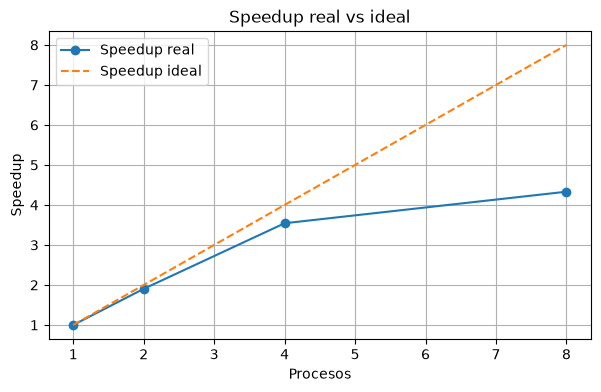

In [108]:
#Gráfica de speedup
plt.figure(figsize=(7, 4))

plt.plot(
    resultados["procesos"],
    resultados["speedup"],
    marker="o",
    label="Speedup real"
)

plt.plot(
    resultados["procesos"],
    resultados["procesos"],
    linestyle="--",
    label="Speedup ideal"
)

plt.title("Speedup real vs ideal")
plt.xlabel("Procesos")
plt.ylabel("Speedup")
plt.legend()
plt.grid()

plt.show()

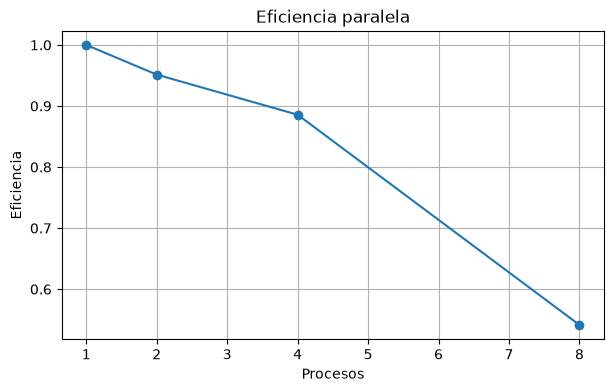

In [109]:
plt.figure(figsize=(7, 4))
plt.plot(
    resultados["procesos"],
    resultados["eficiencia"],
    marker="o"
)
plt.title("Eficiencia paralela")
plt.xlabel("Procesos")
plt.ylabel("Eficiencia")
plt.grid()
plt.show()

In [110]:
mejor = resultados.loc[resultados["tiempo"].idxmin()]

print(f"Tiempo secuencial: {tiempo_secuencial:.4f} s")
print(
    f"Menor tiempo observado: {mejor['tiempo']:.4f} s "
    f"con {int(mejor['procesos'])} proceso(s)."
)

if mejor["procesos"] == 1:
    print("En esta medición, la ejecución secuencial fue la más rápida.")
else:
    print(f"Speedup observado: {mejor['speedup']:.4f}")

print("Los tiempos corresponden a una ejecución por configuración.")

Tiempo secuencial: 156.9124 s
Menor tiempo observado: 36.2297 s con 8 proceso(s).
Speedup observado: 4.3310
Los tiempos corresponden a una ejecución por configuración.


In [111]:
y = df["clase"].to_numpy()
grupos = df["grupo"].to_numpy()

assert X.shape == (len(y), 34)
assert len(y) == len(grupos)

print("X:", X.shape)
print("y:", y.shape)
print("Grupos:", np.unique(grupos).size)

X: (5300, 34)
y: (5300,)
Grupos: 13


## 5. Validación de SVM y Random Forest

Se utiliza validación cruzada estratificada por grupos con 3 folds.
Los recortes de una misma muestra permanecen juntos para evitar
fuga de información entre entrenamiento y prueba.

Ambos modelos utilizan las mismas particiones. El escalado del SVM
se ajusta únicamente con los datos de entrenamiento de cada fold.

In [112]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    make_scorer, precision_score, recall_score, f1_score
)

clases = np.unique(y)

assert df.groupby("clase")["grupo"].nunique().min() >= 3

cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)
particiones = list(cv.split(X, y, groups=grupos))

# Revisar las particiones antes de entrenar.
for fold, (train_idx, test_idx) in enumerate(particiones, 1):
    assert not (
        set(grupos[train_idx]) & set(grupos[test_idx])
    ), "Hay grupos compartidos entre entrenamiento y prueba."

    assert set(y[train_idx]) == set(clases), (
        f"Faltan clases en entrenamiento del fold {fold}."
    )
    assert set(y[test_idx]) == set(clases), (
        f"Faltan clases en prueba del fold {fold}."
    )

    print(f"\nFold {fold}:")
    print(pd.DataFrame({
        "entrenamiento": pd.Series(y[train_idx]).value_counts(),
        "prueba": pd.Series(y[test_idx]).value_counts()
    }).fillna(0).astype(int))

modelos = {
    "SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf")
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=1
    )
}

metricas = {
    "accuracy": "accuracy",
    "precision_macro": make_scorer(
        precision_score, labels=clases,
        average="macro", zero_division=0
    ),
    "recall_macro": make_scorer(
        recall_score, labels=clases,
        average="macro", zero_division=0
    ),
    "f1_macro": make_scorer(
        f1_score, labels=clases,
        average="macro", zero_division=0
    )
}

resumen = []

for nombre, modelo in modelos.items():
    evaluacion = cross_validate(
        modelo,
        X,
        y,
        cv=particiones,
        scoring=metricas,
        n_jobs=1,
        error_score="raise"
    )

    fila = {"modelo": nombre}
    for metrica in metricas:
        valores = evaluacion[f"test_{metrica}"]
        fila[metrica] = valores.mean()

    fila["f1_desviacion"] = evaluacion["test_f1_macro"].std()
    resumen.append(fila)

    print(f"\n{nombre} F1 por fold:", evaluacion["test_f1_macro"])

resumen_modelos = pd.DataFrame(resumen)
display(resumen_modelos.round(4))


Fold 1:
                  entrenamiento  prueba
medio_punto_alto           2020    1100
punto_alto                 1060     100
punto_bajo                  940      80

Fold 2:
                  entrenamiento  prueba
medio_punto_alto           2100    1020
punto_alto                  200     960
punto_bajo                  980      40

Fold 3:
                  entrenamiento  prueba
medio_punto_alto           2120    1000
punto_alto                 1060     100
punto_bajo                  120     900

SVM F1 por fold: [0.2345571  0.25925092 0.21663453]

Random Forest F1 por fold: [0.1476021  0.23274897 0.20191609]


,modelo,accuracy,precision_macro,recall_macro,f1_macro,f1_desviacion
0,SVM,0.4612,0.2188,0.3018,0.2368,0.0175
1,Random Forest,0.3783,0.2018,0.2303,0.1941,0.0352


## 6. Conclusiones

Se procesaron 5300 imágenes de tres tipos de punto de crochet, agrupadas en 13 muestras. De cada imagen se extrajeron 34 características: 18 de LBP y 16 de GLCM. Se verificó que las implementaciones secuencial y paralela produjeran resultados numéricamente equivalentes.

La tabla de tiempos permite comparar la ejecución secuencial con las configuraciones de 2, 4 y 8 procesos. El speedup expresa la aceleración respecto a la ejecución secuencial, mientras que la eficiencia relaciona esa aceleración con el número de procesos. Las mediciones corresponden a una ejecución por configuración y no constituyen un estudio de variabilidad del rendimiento.

En la validación cruzada de tres folds por grupos, SVM obtuvo un accuracy promedio de 0.4612 y un F1 macro de 0.2368. Random Forest obtuvo un accuracy promedio de 0.3783 y un F1 macro de 0.1941. SVM presentó mejores resultados en esta evaluación, aunque el desempeño de ambos modelos fue limitado.

La separación por grupos mantuvo los recortes de una misma muestra juntos durante la validación. Sin embargo, disponer de solamente 13 muestras y de cantidades desiguales de imágenes por clase y fold limita la interpretación de los resultados.

El proyecto implementó y comparó la extracción secuencial y paralela de características. La clasificación requiere mejoras para distinguir satisfactoriamente los tres tipos de punto; como trabajo futuro se propone incorporar más muestras independientes y evaluar otras representaciones de textura.